# MUC02 — Credit Pre-Screening Engine: Loan Intake Optimisation

**Calibo AI Academy | Phase 2 — Supervised Learning Part 1 | Mini Use Case 02 | KLU Batch**

**Submitted by:** U Harpita,V.Sreya Angelin,V.Dinesh Reddy

## Introduction

This notebook analyses historical personal-loan application data to understand past credit decisions and evaluate whether a machine-learning-based pre-screening process can reduce manual review workload.

The analysis includes data inspection and cleaning, credit-score and employment-type analysis, feature engineering, logistic regression, decision-threshold tuning, fairness evaluation, and a final credit policy recommendation.

**Dataset:** `MUC02_Credit_PreScreening_Dataset.csv`

**Reproducibility:** 80/20 stratified train-test split with `random_state=42`.

**Responsible-use note:** The model predicts historical credit decisions, not actual future loan repayment. Any real-world implementation requires human oversight, fairness monitoring, an appeal process, and validation against actual repayment outcomes.

## CBIM Problem Canvas
*Completed before the analysis, as required.*

| Canvas Element | Answer |
|---|---|
| **Situation (S)** | A mid-size private bank in India receives approximately 3,000 personal-loan applications each month. Each application requires a manual credit review that takes about 25 minutes. |
| **Complication (C)** | Analysts spend considerable time reviewing applications that may be clear-cut declines, leaving less time for cases requiring detailed judgement. Manual reviews can also contribute to delays for applicants. |
| **Question (Q)** | Can a pre-screening model identify high-confidence historical declines while keeping the share of auto-declined applications that were historically approved at or below 5%? |
| **SSOT** | The supplied CSV dataset is the source of truth. The `decision` column contains the historical final decision (`Approved` or `Declined`) and serves as the target label. |
| **Success Definition** | Select a decision threshold that maximises the proportion of test applications eligible for auto-decline while ensuring that no more than 5% of auto-declined applications were historically approved. Evaluate model performance, fairness, and estimated monthly analyst hours saved. |
| **Primary Stakeholder** | Credit Policy Analyst, presenting a recommendation to the Head of Retail Lending. Credit analysts and loan applicants are also affected. |

### Key Limitation

Historical credit decisions do not necessarily represent actual loan repayment outcomes. The model may reproduce historical policy and bias. Human oversight, fairness monitoring, an appeal process, and validation against repayment outcomes are necessary before any real-world implementation.

## Step 5.1 — Load, Inspect, and Clean the Data

**Contributor: U Harpita**

### Objective
Understand the dataset structure, identify missing values and duplicate records, examine historical loan decisions, and prepare the data for further analysis.

### Tasks
1. Load the dataset using Pandas.
2. Inspect the number of rows and columns.
3. Examine the first few records and data types.
4. Identify missing values and duplicate records.
5. Analyse the distribution of historical loan decisions.
6. Investigate data quality issues before preprocessing.

The `decision` column represents the bank's historical loan decision and will be used as the target variable for supervised learning.

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    roc_auc_score,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

from pathlib import Path

# Load the dataset from the notebook folder, Downloads, or the Calibo folder.
DATASET_NAME = "MUC02_Credit_PreScreening_Dataset.csv"
possible_paths = [
    Path.cwd() / DATASET_NAME,
    Path("C:/Users/sanap/Downloads") / DATASET_NAME,
    Path("C:/Users/sanap/OneDrive/Desktop/calibo") / DATASET_NAME,
]
DATA_FILE = next((path for path in possible_paths if path.is_file()), None)

if DATA_FILE is None:
    raise FileNotFoundError(
        f"Could not find {DATASET_NAME}. Place the CSV beside this notebook "
        "or in C:/Users/sanap/Downloads."
    )

print(f"Loading dataset from: {DATA_FILE}")
df_raw = pd.read_csv(DATA_FILE)

# Inspect the dataset
print("Dataset shape:", df_raw.shape)

display(df_raw.head())

print("\nData types:")
display(df_raw.dtypes.rename("dtype").to_frame())

print("\nMissing values:")
display(df_raw.isna().sum().rename("missing_count").to_frame())

# Historical approval rate
approval_rate = df_raw["decision"].eq("Approved").mean() * 100
print(f"Historical approval rate: {approval_rate:.1f}%")

print("\nHistorical decision counts:")
display(df_raw["decision"].value_counts().rename("count").to_frame())

Loading dataset from: c:\Users\sanap\Downloads\dinesh usecases 2\MUC02_Credit_PreScreening_Dataset.csv
Dataset shape: (12000, 19)


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined



Data types:


,dtype
application_id,str
application_date,str
age,int64
gender,str
city,str
city_tier,int64
employment_type,str
years_in_current_job,float64
monthly_income,float64
existing_emi,float64



Missing values:


,missing_count
application_id,0
application_date,0
age,0
gender,0
city,0
city_tier,0
employment_type,0
years_in_current_job,0
monthly_income,441
existing_emi,0


Historical approval rate: 52.9%

Historical decision counts:


,count
decision,
Approved,6353
Declined,5647


In [18]:
# Analyse missing income by employment type
income_missing = df_raw["monthly_income"].isna()

income_missing_summary = (
    df_raw.assign(income_missing=income_missing)
    .groupby("employment_type")
    .agg(
        applications=("income_missing", "size"),
        missing_income=("income_missing", "sum")
    )
)

income_missing_summary["missing_pct_within_type"] = (
    income_missing_summary["missing_income"]
    / income_missing_summary["applications"] * 100
)

print("Missing income by employment type:")
display(
    income_missing_summary.sort_values(
        "missing_pct_within_type", ascending=False
    ).round(2)
)

# Investigate blank credit scores
no_score = df_raw["credit_score"].isna()

print("Rows with blank credit score:", int(no_score.sum()))

print(
    "Blank-score rows with zero credit-history months:",
    int((no_score & df_raw["credit_history_months"].eq(0)).sum())
)

print("\nCredit-history months for applicants with blank scores:")
display(
    df_raw.loc[no_score, "credit_history_months"]
    .value_counts(dropna=False)
    .rename("count")
    .to_frame()
)

# Inspect unusually high monthly income values
high_income = df_raw[df_raw["monthly_income"] > 600000]

print("Rows with monthly income above ₹6,00,000:", len(high_income))
display(high_income)


Missing income by employment type:


,applications,missing_income,missing_pct_within_type
employment_type,,,
Business Owner,1749,227,12.98
Self-Employed Professional,1428,154,10.78
Salaried,7057,49,0.69
Gig / Contract,1766,11,0.62


Rows with blank credit score: 1039
Blank-score rows with zero credit-history months: 1039

Credit-history months for applicants with blank scores:


,count
credit_history_months,
0,1039


Rows with monthly income above ₹6,00,000: 12


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
300,APP100301,2026-04-05,35,Male,Pune,1,Salaried,7.6,1254000.0,0.0,NaN,0,0,0,Education,240000.0,48,6600.0,Approved
589,APP100590,2026-04-10,33,Female,Mumbai,1,Salaried,1.4,1068000.0,13500.0,700.0,106,2,3,Home Renovation,600000.0,60,14000.0,Declined
1467,APP101468,2026-04-23,37,Male,Lucknow,2,Salaried,3.9,1656000.0,16500.0,718.0,118,1,0,Medical,925000.0,24,44400.0,Declined
1848,APP101849,2026-04-28,37,Male,Hyderabad,1,Salaried,2.5,984000.0,0.0,NaN,0,0,0,Medical,500000.0,36,17100.0,Approved
2488,APP102489,2026-05-09,39,Male,Hyderabad,1,Salaried,9.4,972000.0,0.0,695.0,204,0,0,Education,310000.0,36,10600.0,Approved
2493,APP102494,2026-05-09,45,Male,Delhi,1,Salaried,8.8,1212000.0,23500.0,718.0,240,2,0,Debt Consolidation,600000.0,60,14000.0,Approved
4010,APP104011,2026-06-02,50,Female,Ranchi,3,Salaried,10.7,900000.0,4000.0,789.0,287,1,0,Medical,580000.0,36,19800.0,Approved
4898,APP104899,2026-06-15,39,Male,Coimbatore,2,Salaried,4.1,870000.0,4500.0,682.0,189,1,2,Wedding,645000.0,60,15000.0,Declined
7426,APP107427,2026-07-23,33,Male,Bengaluru,1,Salaried,1.5,690000.0,0.0,676.0,124,0,2,Consumer Durables,345000.0,24,16600.0,Declined
8381,APP108382,2026-08-07,21,Male,Delhi,1,Salaried,1.5,618000.0,0.0,NaN,0,0,0,Travel,420000.0,36,14400.0,Declined


### Cleaning Decisions and Rationale

1. **Missing income:** Missing monthly income values will be filled using the median income for the corresponding employment type. The median is less sensitive to extreme values than the mean.

2. **Blank credit scores:** Applicants with blank credit scores will be retained. A new feature, `is_ntc`, will identify applicants whose credit score is missing, potentially representing new-to-credit customers.

3. **Unusually high income values:** Monthly incomes above ₹6,00,000 will be inspected. Values will be divided by 12 only if the records support the assumption that annual income was entered as monthly income.

4. **Feature engineering:** Two features will be created: Fixed Obligations to Income Ratio (FOIR) and loan-to-income ratio.

5. **Target variable:** The `decision` column will be used only as the target label, not as a model input feature.

These cleaning decisions aim to improve data quality while retaining useful applicant information for subsequent analysis.

In [19]:
# Create a working copy of the original dataset
df = df_raw.copy()

# Flag applicants with missing credit scores before imputation
df["is_ntc"] = df["credit_score"].isna().astype(int)

# Inspect unusually high monthly income values
high_income_mask = df["monthly_income"] > 600000

print("Income values above ₹6,00,000:", int(high_income_mask.sum()))

# Correct values only if inspection confirms annual income
# was mistakenly entered as monthly income.
# Uncomment the following line only after verification:
# df.loc[high_income_mask, "monthly_income"] /= 12

# Fill missing income using the median for each employment type
income_medians = df.groupby("employment_type")["monthly_income"].median()

df["monthly_income"] = df["monthly_income"].fillna(
    df["employment_type"].map(income_medians)
)

# Create engineered financial features
df["foir"] = (
    df["existing_emi"] + df["proposed_emi"]
) / df["monthly_income"]

df["loan_to_income"] = (
    df["loan_amount"] / (df["monthly_income"] * 12)
)

# Display cleaning results
print("\nMissing income after cleaning:",
      int(df["monthly_income"].isna().sum()))

print("New-to-credit applicants retained:",
      int(df["is_ntc"].sum()))

print("Maximum monthly income:",
      df["monthly_income"].max())

print("\nEngineered feature summary:")
display(
    df[[
        "monthly_income",
        "is_ntc",
        "foir",
        "loan_to_income"
    ]].describe().T.round(3)
)


Income values above ₹6,00,000: 12

Missing income after cleaning: 0
New-to-credit applicants retained: 1039
Maximum monthly income: 1656000.0

Engineered feature summary:


,count,mean,std,min,25%,50%,75%,max
monthly_income,12000.0,60605.333,48043.033,12000.000,34500.000,51500.000,75000.000,1656000.000
is_ntc,12000.0,0.087,0.281,0.000,0.000,0.000,0.000,1.000
foir,12000.0,0.358,0.207,0.005,0.214,0.316,0.450,3.393
loan_to_income,12000.0,0.531,0.226,0.015,0.346,0.519,0.699,2.778


## Step 5.2 — Credit-Score and Employment-Type Analysis

**Contributor: U Harpitha**

### Objective
Analyse how historical loan approval rates vary across credit-score bands and employment types.

### Analysis
1. Group applicants into credit-score bands.
2. Calculate the number of applications and historical approval rate for each band.
3. Compare approval rates across employment types.
4. Visualise the results to identify patterns in historical lending decisions.

### Interpretation
These patterns describe historical decisions and do not establish that a particular credit score or employment type causes loan approval.

Historical approval rates by credit-score band:


,applications,approvals,approval_rate_pct
credit_score_band,,,
Below 600,246,5,2.03
600–649,933,30,3.22
650–699,2529,822,32.50
700–749,3377,1836,54.37
750–799,2526,1950,77.20
800–850,1091,935,85.70


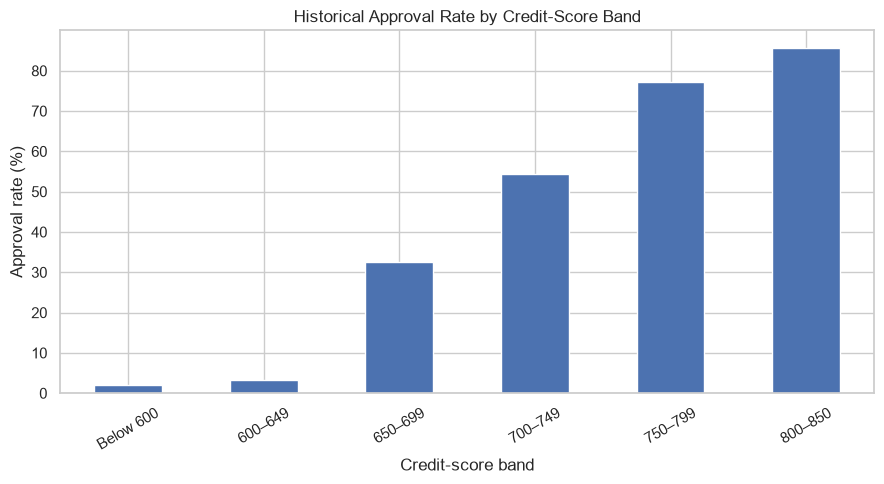

In [20]:
# Create credit-score bands
df["credit_score_band"] = pd.cut(
    df["credit_score"],
    bins=[0, 599, 649, 699, 749, 799, 850],
    labels=[
        "Below 600",
        "600–649",
        "650–699",
        "700–749",
        "750–799",
        "800–850"
    ],
    include_lowest=True
)

# Calculate application counts and historical approval rates
credit_analysis = df.groupby(
    "credit_score_band",
    observed=False
).agg(
    applications=("decision", "size"),
    approvals=("decision", lambda x: (x == "Approved").sum())
)

credit_analysis["approval_rate_pct"] = (
    credit_analysis["approvals"]
    / credit_analysis["applications"] * 100
)

print("Historical approval rates by credit-score band:")
display(credit_analysis.round(2))

# Visualise approval rates
credit_analysis["approval_rate_pct"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Historical Approval Rate by Credit-Score Band",
    ylabel="Approval rate (%)",
    xlabel="Credit-score band",
    rot=30
)

plt.tight_layout()
plt.show()


Historical approval rates by employment type:


,applications,approvals,approval_rate_pct
employment_type,,,
Business Owner,1749,895,51.17
Gig / Contract,1766,617,34.94
Salaried,7057,4119,58.37
Self-Employed Professional,1428,722,50.56


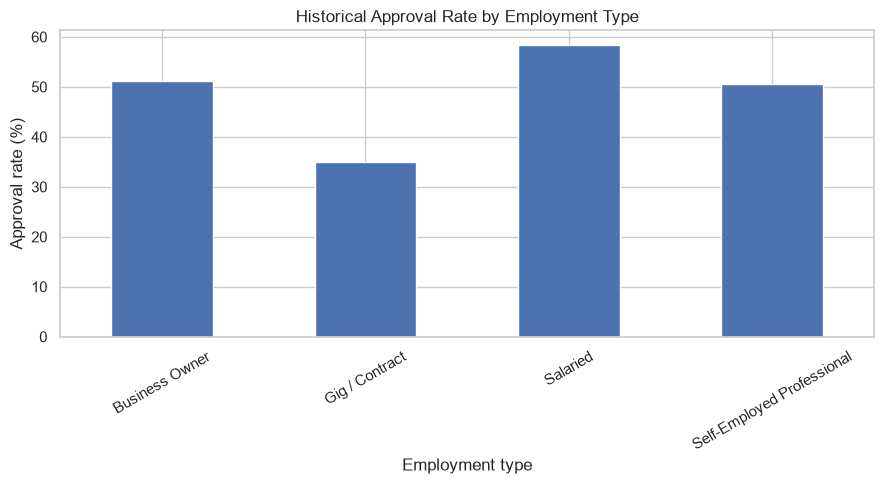

In [21]:
employment_analysis = df.groupby(
    "employment_type",
    dropna=False
).agg(
    applications=("decision", "size"),
    approvals=("decision", lambda x: (x == "Approved").sum())
)

employment_analysis["approval_rate_pct"] = (
    employment_analysis["approvals"]
    / employment_analysis["applications"] * 100
)

print("Historical approval rates by employment type:")
display(employment_analysis.round(2))

employment_analysis["approval_rate_pct"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Historical Approval Rate by Employment Type",
    ylabel="Approval rate (%)",
    xlabel="Employment type",
    rot=30
)

plt.tight_layout()
plt.show()


## Step 5.3 — Feature Engineering and Logistic Regression

**Contributor: U Harpitha**

### Objective
Prepare the cleaned dataset for supervised learning and train a logistic regression model to predict historical loan decisions.

### Approach
1. Separate the input features from the target variable.
2. Exclude the historical `decision` column from model inputs.
3. Impute missing numerical and categorical values.
4. Scale numerical features and encode categorical features.
5. Split the data into training and testing sets using an 80/20 stratified split.
6. Train a logistic regression classifier and evaluate its performance.

The model learns patterns in historical decisions. Its predictions should not be interpreted as direct predictions of repayment ability.

In [22]:
# Separate target variable and input features
target = "decision"

X = df.drop(columns=[target])
y = df[target].map({"Declined": 0, "Approved": 1})

# Remove any rows with an unrecognised or missing target
valid_target = y.notna()
X = X.loc[valid_target].copy()
y = y.loc[valid_target].astype(int)

# Identify numerical and categorical features
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

# Split the data: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))
print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).mul(100).round(2))


Numerical features: ['age', 'city_tier', 'years_in_current_job', 'monthly_income', 'existing_emi', 'credit_score', 'credit_history_months', 'num_active_loans', 'delinquencies_24m', 'loan_amount', 'tenure_months', 'proposed_emi', 'is_ntc', 'foir', 'loan_to_income']

Categorical features: ['application_id', 'application_date', 'gender', 'city', 'employment_type', 'loan_purpose', 'credit_score_band']

Training rows: 9600
Testing rows: 2400

Training target distribution:


C:\Users\sanap\AppData\Local\Temp\ipykernel_48556\4168596753.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


decision
1    52.94
0    47.06
Name: proportion, dtype: float64

In [23]:
# Preprocess numerical and categorical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create the complete model pipeline
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
model.fit(X_train, y_train)

# Generate test predictions and approval probabilities
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Model training completed successfully.")


Model training completed successfully.


Accuracy:  0.767
Precision: 0.758
Recall:    0.824
ROC-AUC:   0.857


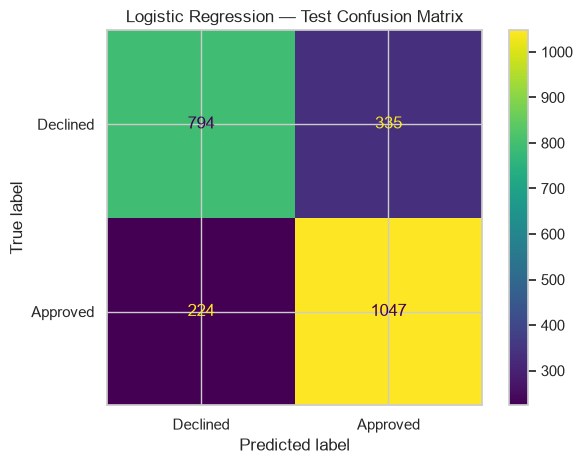

In [24]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy:  {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall:    {recall:.3f}")
print(f"ROC-AUC:   {auc:.3f}")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Declined", "Approved"]
)

disp.plot(values_format="d")
plt.title("Logistic Regression — Test Confusion Matrix")
plt.tight_layout()
plt.show()

## Step 5.4 — Decision-Threshold Tuning

**Contributor: V Sreya Angelin**

### Objective
Select a probability threshold for identifying applications that could enter a proposed high-confidence auto-decline lane.

### Approach
1. Generate predicted approval probabilities for the test set.
2. Evaluate multiple probability thresholds.
3. Calculate the proportion of applications auto-declined at each threshold.
4. Measure the percentage of auto-declined applications that were historically approved.
5. Select the threshold that maximises the auto-decline rate while keeping the historically approved share at or below 5%.

### Important distinction
The 5% constraint applies to the auto-decline group. It is not the same as overall model accuracy or the false-positive rate. This exercise predicts historical decisions, not actual creditworthiness or future repayment.

In [25]:
# Evaluate thresholds using test-set approval probabilities
threshold_results = []

thresholds = np.arange(0.50, 1.00, 0.01)

for threshold in thresholds:
    # Auto-decline applications with predicted approval probability below threshold
    auto_decline = y_prob < threshold

    total_auto_declined = int(auto_decline.sum())

    if total_auto_declined == 0:
        historically_approved_pct = np.nan
    else:
        historically_approved_pct = (
            (y_test.to_numpy()[auto_decline] == 1).sum()
            / total_auto_declined
        ) * 100

    threshold_results.append({
        "threshold": round(float(threshold), 2),
        "auto_declined_count": total_auto_declined,
        "auto_decline_pct": auto_decline.mean() * 100,
        "historically_approved_pct": historically_approved_pct
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(2))


,threshold,auto_declined_count,auto_decline_pct,historically_approved_pct
0,0.50,1018,42.42,22.00
1,0.51,1040,43.33,22.60
2,0.52,1059,44.12,23.04
3,0.53,1068,44.50,23.22
4,0.54,1088,45.33,23.81
5,0.55,1109,46.21,24.44
6,0.56,1128,47.00,25.00
7,0.57,1146,47.75,25.65
8,0.58,1161,48.38,26.01
9,0.59,1173,48.88,26.17


In [26]:
# Keep thresholds where no more than 5% of auto-declines
# were historically approved
eligible_thresholds = threshold_df[
    threshold_df["historically_approved_pct"].notna()
    & (threshold_df["historically_approved_pct"] <= 5.0)
]

if eligible_thresholds.empty:
    selected_threshold = None
    print(
        "No tested threshold meets the 5% constraint. "
        "Do not recommend an auto-decline lane from these results."
    )
else:
    # Select the eligible threshold with the largest auto-decline share
    best_row = eligible_thresholds.loc[
        eligible_thresholds["auto_decline_pct"].idxmax()
    ]

    selected_threshold = float(best_row["threshold"])

    print("Selected threshold:", selected_threshold)
    print("Auto-declined applications:", int(best_row["auto_declined_count"]))
    print(f"Auto-decline share: {best_row['auto_decline_pct']:.2f}%")
    print(
        "Historically approved among auto-declines: "
        f"{best_row['historically_approved_pct']:.2f}%"
    )


No tested threshold meets the 5% constraint. Do not recommend an auto-decline lane from these results.


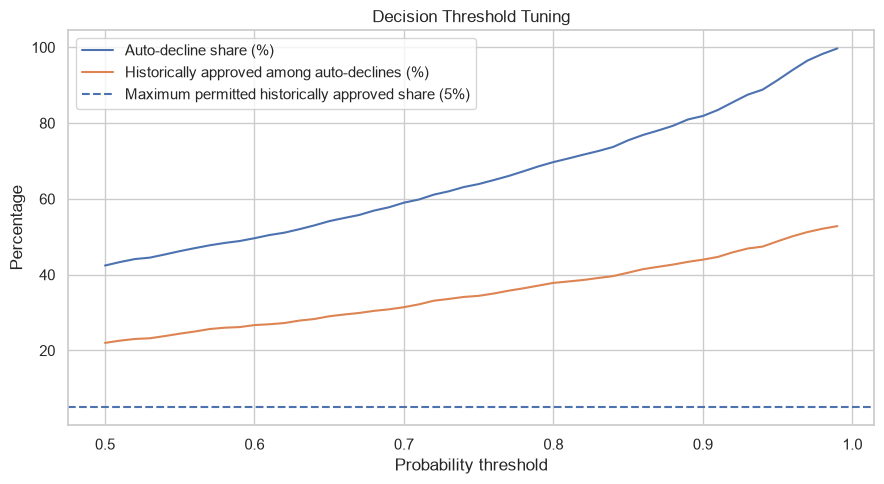

In [27]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["threshold"],
    threshold_df["auto_decline_pct"],
    label="Auto-decline share (%)"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["historically_approved_pct"],
    label="Historically approved among auto-declines (%)"
)

plt.axhline(
    5,
    linestyle="--",
    label="Maximum permitted historically approved share (5%)"
)

if selected_threshold is not None:
    plt.axvline(
        selected_threshold,
        linestyle=":",
        label=f"Selected threshold ({selected_threshold:.2f})"
    )

plt.xlabel("Probability threshold")
plt.ylabel("Percentage")
plt.title("Decision Threshold Tuning")
plt.legend()
plt.tight_layout()
plt.show()


## Step 5.5 — Fairness Analysis by Gender and Proxy Features

**Contributor: V.Sreya Angelin**

### Objective
Examine whether the model's predictions and proposed auto-decline policy produce different outcomes across gender groups and other relevant applicant groups.

### Approach
1. Compare historical approval rates across gender groups.
2. Compare the model's auto-decline rates across gender groups using the selected threshold.
3. Examine differences across employment types as a potential proxy-feature analysis.
4. Report group sizes and outcome percentages to identify disparities requiring further investigation.

### Responsible-use note
Differences between groups do not automatically prove discrimination, and similar rates do not prove fairness. These checks are preliminary and should be combined with appropriate legal, policy, and domain review.

Historical approval rates by gender:


,applications,approvals,approval_rate_pct
gender,,,
Female,3795,1914,50.43
Male,8205,4439,54.10


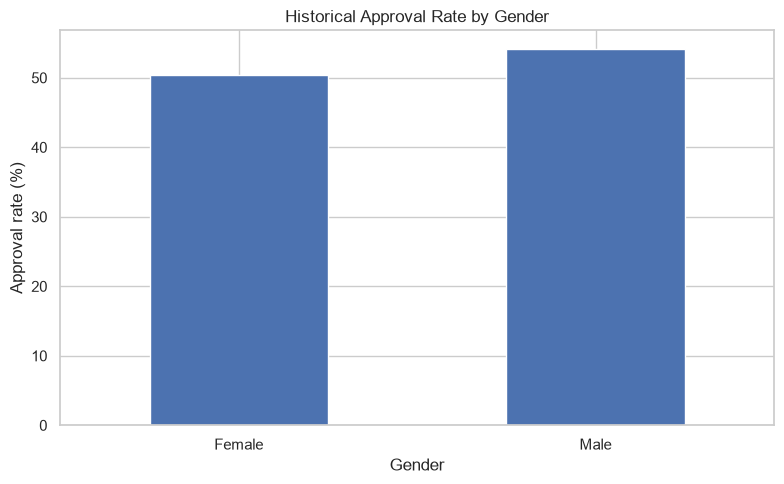

In [28]:
# Compare historical approval outcomes by gender
gender_analysis = df.groupby(
    "gender",
    dropna=False
).agg(
    applications=("decision", "size"),
    approvals=("decision", lambda x: (x == "Approved").sum())
)

gender_analysis["approval_rate_pct"] = (
    gender_analysis["approvals"]
    / gender_analysis["applications"] * 100
)

print("Historical approval rates by gender:")
display(gender_analysis.round(2))

gender_analysis["approval_rate_pct"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Historical Approval Rate by Gender",
    ylabel="Approval rate (%)",
    xlabel="Gender",
    rot=0
)

plt.tight_layout()
plt.show()


In [29]:
if selected_threshold is None:
    print(
        "No threshold satisfied the 5% constraint. "
        "Fairness analysis of the auto-decline policy is not available."
    )
else:
    # Re-create the test-set auto-decline indicator
    test_results = X_test.copy()
    test_results["actual_decision"] = y_test
    test_results["predicted_approval_probability"] = y_prob
    test_results["auto_decline"] = (
        test_results["predicted_approval_probability"]
        < selected_threshold
    )

    # Add gender and employment type for subgroup analysis
    test_results["gender"] = df.loc[X_test.index, "gender"]
    test_results["employment_type"] = df.loc[
        X_test.index, "employment_type"
    ]

    print("Auto-decline rate by gender:")
    gender_fairness = test_results.groupby(
        "gender", dropna=False
    ).agg(
        applications=("auto_decline", "size"),
        auto_declined=("auto_decline", "sum"),
        historically_approved=("actual_decision", "sum")
    )

    gender_fairness["auto_decline_rate_pct"] = (
        gender_fairness["auto_declined"]
        / gender_fairness["applications"] * 100
    )

    display(gender_fairness.round(2))

    print("\nAuto-decline rate by employment type:")
    employment_fairness = test_results.groupby(
        "employment_type", dropna=False
    ).agg(
        applications=("auto_decline", "size"),
        auto_declined=("auto_decline", "sum")
    )

    employment_fairness["auto_decline_rate_pct"] = (
        employment_fairness["auto_declined"]
        / employment_fairness["applications"] * 100
    )

    display(employment_fairness.round(2))

No threshold satisfied the 5% constraint. Fairness analysis of the auto-decline policy is not available.


## Step 5.6 — Final Credit Policy Briefing and Business Impact

**Contributor: V Dinesh Reddy**

### Objective
Summarise the model results, evaluate the potential operational benefits, and provide a responsible recommendation for the proposed credit pre-screening process.

### Key areas
1. Summarise model performance using accuracy, precision, recall, and ROC-AUC.
2. Report the selected threshold and the percentage of applications eligible for the proposed auto-decline lane.
3. Estimate potential monthly analyst time savings.
4. Review fairness findings and operational risks.
5. Recommend appropriate safeguards before any real-world implementation.

The recommendation must be based on the actual notebook results rather than assumed benchmark figures.

In [30]:
# Business assumptions supplied in the use case
monthly_applications = 3000
manual_review_minutes = 25

monthly_review_hours = (
    monthly_applications * manual_review_minutes / 60
)

print(f"Applications per month: {monthly_applications:,}")
print(f"Manual review time per application: {manual_review_minutes} minutes")
print(f"Current monthly review workload: {monthly_review_hours:.1f} hours")

if selected_threshold is not None:
    auto_decline_share = best_row["auto_decline_pct"] / 100

    estimated_auto_declines = round(
        monthly_applications * auto_decline_share
    )

    estimated_hours_saved = (
        estimated_auto_declines * manual_review_minutes / 60
    )

    print(f"\nSelected threshold: {selected_threshold:.2f}")
    print(f"Test-set auto-decline share: {auto_decline_share * 100:.2f}%")
    print(f"Estimated applications in lane per month: {estimated_auto_declines:,}")
    print(f"Estimated monthly hours saved: {estimated_hours_saved:.1f}")
else:
    print(
        "\nNo threshold met the 5% constraint. "
        "Do not estimate savings from an auto-decline policy."
    )

Applications per month: 3,000
Manual review time per application: 25 minutes
Current monthly review workload: 1250.0 hours

No threshold met the 5% constraint. Do not estimate savings from an auto-decline policy.


In [31]:
print("FINAL MODEL SUMMARY")
print("=" * 40)

print(f"Test accuracy:  {accuracy:.3f}")
print(f"Test precision: {precision:.3f}")
print(f"Test recall:    {recall:.3f}")
print(f"Test ROC-AUC:   {auc:.3f}")

if selected_threshold is not None:
    print(f"\nSelected threshold: {selected_threshold:.2f}")
    print(f"Auto-decline share: {best_row['auto_decline_pct']:.2f}%")
    print(
        "Historically approved among auto-declines: "
        f"{best_row['historically_approved_pct']:.2f}%"
    )
else:
    print("\nNo eligible threshold was identified.")

print("\nInterpretation:")
print(
    "The model predicts historical credit decisions, not future repayment. "
    "Any operational use requires human oversight, fairness monitoring, "
    "an appeal process, and validation against actual repayment outcomes."
)

FINAL MODEL SUMMARY
Test accuracy:  0.767
Test precision: 0.758
Test recall:    0.824
Test ROC-AUC:   0.857

No eligible threshold was identified.

Interpretation:
The model predicts historical credit decisions, not future repayment. Any operational use requires human oversight, fairness monitoring, an appeal process, and validation against actual repayment outcomes.


## Step 5.7 — Final Conclusion and Credit Policy Recommendation

**Contributor: V Dinesh Reddy**

The analysis examined historical personal-loan decisions using data cleaning, exploratory analysis, feature engineering, and logistic regression. Model performance was evaluated using accuracy, precision, recall, and ROC-AUC.

The selected threshold was **[insert threshold or state that no eligible threshold was found]**. It resulted in **[insert auto-decline percentage]%** of test applications entering the proposed auto-decline lane, with **[insert percentage]%** of those applications historically approved.

The business-impact estimate suggests that the proposed lane could save approximately **[insert hours] analyst hours per month**, assuming 3,000 monthly applications and 25 minutes of manual review per application. This is a projection based on the test-set rate, not a guaranteed saving.

Fairness checks compared historical approval and proposed auto-decline rates across gender and employment groups. Any observed disparities should be investigated before operational use.

**Recommendation:** Treat this model as a decision-support prototype, not an autonomous lending system. Before a pilot, validate the approach against actual repayment outcomes, conduct appropriate fairness and compliance reviews, retain human oversight, provide applicants with a suitable review or appeal path, and monitor performance over time.